# Perceptron From Scratch: Hyperparameter Sensitivity & Decision Boundaries

A hands-on implementation of the perceptron learning algorithm, exploring how the learning rate, data ordering, and random initialization affect convergence, and visualizing how the decision boundary evolves during training on the Iris dataset.

## Preparation Steps

In [ ]:
# Import all necessary python packages
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [ ]:
# ### Loading the Iris data

s = os.path.join('https://archive.ics.uci.edu', 'ml',
                 'machine-learning-databases', 'iris','iris.data')
s = s.replace("\\","/");
print('URL:', s)
df = pd.read_csv(s,header=None,encoding='utf-8')


URL: https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data


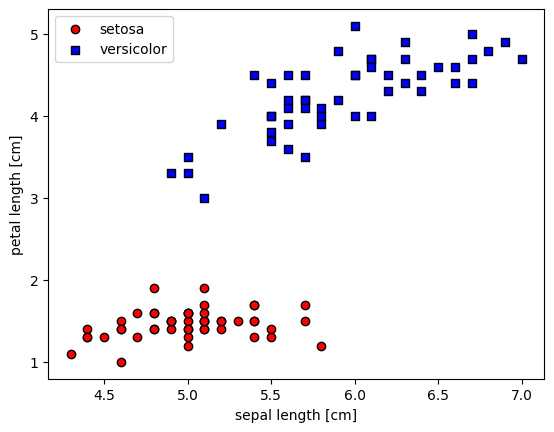

In [ ]:
# select setosa and versicolor
y = df.iloc[0:100, 4].values
y = np.where(y == 'Iris-setosa', -1, 1)

# extract sepal length and petal length
X = df.iloc[:100, [0, 2]].values

# plot data
plt.scatter(X[:50, 0], X[:50, 1],
            color='red', marker='o', label='setosa', edgecolor='black')
plt.scatter(X[50:100, 0], X[50:100, 1],
            color='blue', marker='s', label='versicolor', edgecolor='black')

plt.xlabel('sepal length [cm]')
plt.ylabel('petal length [cm]')
plt.legend(loc='upper left')


# plt.savefig('images/02_06.png', dpi=300)
plt.show()

-----------------------
-----------------------
-----------------------



## <font color='#008DFF'> **Section 0: Manual Perceptron Training**

Below you can see 5 points of the data set, all labeled as 'setosa'.

In [ ]:
X[5:10], y[5:10]

(array([[5.4, 1.7],
        [4.6, 1.4],
        [5. , 1.5],
        [4.4, 1.4],
        [4.9, 1.5]]),
 array([-1, -1, -1, -1, -1]))

Starting from initial weights $w_0 = 5.0$, $w_1 = -0.1$, $w_2 = 4.5$ (where $w_0$ is the bias), this section walks through the perceptron's weight updates by hand for data points 5, 6, and 7, using $\eta = 0.1$ and labels $y,\hat{y}\in\{-1,1\}$.

Data Point 5:

z = 5 + (-0.1) * (5.4) + (4.5) * (1.7) = 12.11

activation(z) = +1

y-predicted != y-actual -> +1 != -1 -> error -> update weights

w0 = w0 - n * (y-predicted - y-actual) = 5 - (0.1) * (1 - (-1)) = 4.8

w1 = w1 - n * (y-predicted - y-actual) * x1 = -0.1 - (0.1) * (1 - (-1)) * (5.4) = -1.18

w2 = w2 - n * (y-predicted - y-actual) * x2 = 4.5 - (0.1) * (1 - (-1)) * (1.7) = 4.16

New Weights After Update: (w0, w1, w2) = (4.8, -1.18, 4.16)

Data Point 6:

z = 4.8 + (-1.18) * (4.6) + (4.16) * (1.4) = 5.196

activation(z) = +1

y-predicted != y-actual -> +1 != -1 -> error -> update weights

w0 = w0 - n * (y-predicted - y-actual) = 4.8 - (0.1) * (1 - (-1)) = 4.6

w1 = w1 - n * (y-predicted - y-actual) * x1 = -1.18 - (0.1) * (1 - (-1)) * (4.6) = -2.1

w2 = w2 - n * (y-predicted - y-actual) * x2 = 4.16 - (0.1) * (1 - (-1)) * (1.4) = 3.88

New Weights After Update: (w0, w1, w2) = (4.6, -2.1, 3.88)

Data Point 7:

z = 4.6 + (-2.1) * (5) + (3.88) * (1.5) = -0.8
activation(z) = -1

y-predicted == y-actual -> -1 == -1 -> no error -> no update weights

Weights After Data Point 7: (w0, w1, w2) = (4.6, -2.1, 3.88)

These are the weights of the perceptron after data points 5, 6, 7 (starting at 5 for the data points).

-----------------------
-----------------------
-----------------------


## <font color='#008DFF'> **Section 1: Perceptron Code Modification**

The following code is a perceptron implementation.

In [ ]:
import numpy as np
import copy
class Perceptron(object):
  """Perceptron classifier.

    Parameters
    ------------
    n_iter : int
      Passes over the training dataset.
    random_state : int
      Random number generator seed for random weight
      initialization.
    eta : float
      Learning rate for model

    Attributes
    -----------
    w_ : 1d-array
      Weights after fitting.
    errors_ : list
      Number of misclassifications (updates) in each epoch.
    iter_trained : int
      The number of iterations it took for training.
    weightHistory : dictionary
      dictionary with key - int - iteration # and value - list of weights after being processed

    """
  ###Added another parameter to the intitialization function of the Perceptron class.
  ###This new parameter: eta. This has a default value of 1.0.
  ###This parameter is the learning rate of the model
  def __init__(self, eta=0.01, n_iter=50, random_state=1):
    ###Initialized learning rate based on parameters passed
    self.eta = eta
    self.n_iter = n_iter
    self.random_state = random_state
    self.iter_trained = -1

  def fit(self, X, y):
    """Fit training data.

    Parameters
    ----------
    X : {array-like}, shape = [n_examples, n_features]
      Training vectors, where n_examples is the number of examples and
      n_features is the number of features.
    y : array-like, shape = [n_examples]
      Target values.

    Returns
    -------
    self : object

    """
    rgen = np.random.RandomState(self.random_state)
    self.w_ = rgen.normal(loc=0.0, scale=0.01, size=1 + X.shape[1])
    self.errors_ = []

    ###Initialize Dictionary Variable. This will store the historical weights of this model.
    ###The key of the Dictionary is the Iteration #
    ###The value of the Dictionary is the Weights of the Model after a Data Point has been processed
    self.weightHistory = {}
    for i in range(self.n_iter):
      errors = 0
      ### Initialize the list of weights in the dictionary for this iteration to a blank list
      self.weightHistory[i] = []
      for xi, target in zip(X, y):
        ###update = self.predict(xi) - target
        ###The update value should be the predicted minus the actual value times the learning rate
        update = self.eta * (self.predict(xi) - target)
        ###self.w_[1:] += update * xi
        ###Since the update value is calculated using predicted minus actual, we multiply the update value by x-value of the data point
        ###Then we subtract the product from the existing weights.
        self.w_[1:] -= update * xi
        ###self.w_[0] += update
        ###Just like the other weights. We subtract the update value from w0 since update is equal to eta * (predicted - actual)
        ###If we did (actual - predicted) then we could do weight += update
        self.w_[0] -= update
        ###We update the weight history dictionary
        ###We are updating the dictionary where key = iteration #
        ###Before this line the weightHistory[key] = []
        ###We use .extend function to append the newly updated weight list to weightHistory[key]
        self.weightHistory[i].append(copy.deepcopy(self.w_))
        errors += int(update != 0.0)
      self.errors_.append(errors)
      ###We update the iter_trained with the iteration # we are currently on
      ###The value is i + 1 because i starts at 0 for the for loop. However, when i = 0, that is the first iteration
      ###This is why we do i + 1, so that we can accurately track what iteration we are on.
      self.iter_trained = i + 1

      ###Check if there was any errors during this epoch
      ###If there was, do another epoch (another for loop iteration)
      ###The reason being is that the model was not able to predict all the values in X correctly
      ###So after updating the weights of the model, we will run it again to verify if the new weights can accurately predict the target labels
      ###If there were no errors (the model was able to predict the targets 100% accurately) we will exit the for loop - no more iterations
      ###We then return self
      if errors == 0:
       break # exit for loop - only if no errors detected
    return self
  def net_input(self, X):
    """Calculate net input"""
    return np.dot(X, self.w_[1:]) + self.w_[0]
  def predict(self, X):
    """Return class label after unit step"""
    return np.where(self.net_input(X) >= 0.0, 1, -1)

The starter perceptron implementation above had several bugs and omissions. This section fixes them: the buggy lines are commented out and replaced with corrected code, the `fit` function is updated to stop early once no more weight updates are needed and to record the number of iterations required, and the perceptron now keeps a history of its weights after each point is processed. Each fix is marked with a comment in place of the original "do-nothing" code.

-----------------------
-----------------------
-----------------------


## <font color='#008DFF'> **Section 2: Experimenting with hyperparameters**

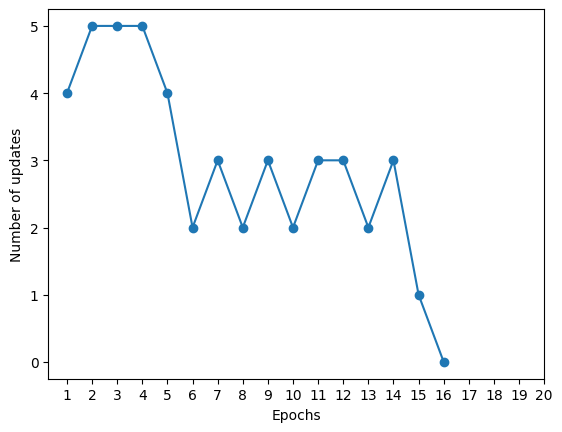

In [ ]:
ppn = Perceptron(eta=0.0001, n_iter=20, random_state=1)

ppn.fit(X, y)

plt.plot(range(1, len(ppn.errors_) + 1), ppn.errors_, marker='o')
plt.xticks(range(1, 21))  # Set integer x-axis labels
plt.xlabel('Epochs')
plt.ylabel('Number of updates')


plt.show()

This section experiments with the hyperparameter $\eta$, the learning rate, using the corrected perceptron from the previous section. It covers: finding learning-rate values that make training converge in 10, 20, 30, and 40 iterations; testing whether raising $\eta$ always reduces the number of iterations needed; comparing how different random-state seeds affect convergence at a fixed $\eta$; and, based on those observations, evaluating whether binary search would be a sound strategy for finding a learning rate that hits a target number of iterations.

Below is the code I will use to determine what learning rate is needed for the process to converge in 10, 20, 30, 40 iterations.
<br>
```
ppn = Perceptron(eta=0.0001, n_iter=200, random_state=1)
ppn.fit(X,y)
print(ppn.iter_trained)
```

In [ ]:
# Part (i)
# Determining learning rate for 10 iterations
ppn = Perceptron(eta=0.0003, n_iter=200, random_state=1)
ppn.fit(X,y)
print("Learning rate to get 10 iterations: " + f"{ppn.eta:.4f}")
print("Iterations: " + str(ppn.iter_trained))

# Determining learning rate for 20 iterations
ppn = Perceptron(eta=0.000049, n_iter=200, random_state=1)
ppn.fit(X,y)
print("Learning rate to get 20 iterations: " + f"{ppn.eta:.6f}")
print("Iterations: " + str(ppn.iter_trained))

# Determining learning rate for 30 iterations
ppn = Perceptron(eta=0.00002, n_iter=200, random_state=1)
ppn.fit(X,y)
print("Learning rate to get 30 iterations: " + f"{ppn.eta:.5f}")
print("Iterations: " + str(ppn.iter_trained))

# Determining learning rate for 40 iterations
ppn = Perceptron(eta=0.00001, n_iter=200, random_state=1)
ppn.fit(X,y)
print("Learning rate to get 40 iterations: " + f"{ppn.eta:.5f}")
print("Iterations: " + str(ppn.iter_trained))


Learning rate to get 10 iterations: 0.0003
Iterations: 10
Learning rate to get 20 iterations: 0.000049
Iterations: 20
Learning rate to get 30 iterations: 0.00002
Iterations: 30
Learning rate to get 40 iterations: 0.00001
Iterations: 40


In [ ]:
# Part (ii)
# Increasing the learning rate (n / eta) in some cases reduces the number of iterations to converge.
# Or in other cases keeps the number the same. However, it is NOT always the case.
# There are cases where increasing the learning rate will increase the number of iterations to converge.
# The reason is that if the learning rate gets to large, it may over correct the model to the other direction.
# This overcorrection may in some cases lead to more iterations being ran in order for the model to converge.
# Below you will see code demonstrating the process of increasing the learning rate and then running the model to see the # of iterations

# Run 20 Tests Increasing Learning rate each time in order to see its effect on # of iterations
for test_iter in range(1, 21):
  # Set the learning rate for the current test (will always be higher than the previous for loop iteration)
  eta = 0.0001 * test_iter * 3
  # Initialize Perceptron Model with learning rate
  ppn = Perceptron(eta=eta, n_iter=100, random_state=2)
  # Fit Model to X, y data
  ppn.fit(X,y)
  # Print Findings
  print("Learning rate: " + f"{ppn.eta:.5f}" + " - Number of Iterations To Converge: " + str(ppn.iter_trained))


# As you can see from the tests we ran. Increasing the learning rate doesn't always lead to a reduction (or equal number) of iterations
# As I mentioned before this can be attributed to the algorithm used to determine the new weights of the model
# We adjust the weights of the model by the difference of predicted y-value and the actual y-value multiplied by the learning rate
# We do factor in the difference as it will move the weights in the direction of the actual y-value.
# The learning rate determines how far we move the weights in the direction of the actual y-value.
# As demonstrated in the tests, sometimes the update to the weights may be greater than what is actually need, leading to more iterations


Learning rate: 0.00030 - Number of Iterations To Converge: 13
Learning rate: 0.00060 - Number of Iterations To Converge: 9
Learning rate: 0.00090 - Number of Iterations To Converge: 10
Learning rate: 0.00120 - Number of Iterations To Converge: 7
Learning rate: 0.00150 - Number of Iterations To Converge: 8
Learning rate: 0.00180 - Number of Iterations To Converge: 9
Learning rate: 0.00210 - Number of Iterations To Converge: 6
Learning rate: 0.00240 - Number of Iterations To Converge: 6
Learning rate: 0.00270 - Number of Iterations To Converge: 6
Learning rate: 0.00300 - Number of Iterations To Converge: 6
Learning rate: 0.00330 - Number of Iterations To Converge: 8
Learning rate: 0.00360 - Number of Iterations To Converge: 7
Learning rate: 0.00390 - Number of Iterations To Converge: 8
Learning rate: 0.00420 - Number of Iterations To Converge: 4
Learning rate: 0.00450 - Number of Iterations To Converge: 4
Learning rate: 0.00480 - Number of Iterations To Converge: 4
Learning rate: 0.00510

In [ ]:
# Part (iii)

# Set learning rate, will be used for both perceptron models
eta = 0.0004

# Build first perceptron model
ppn_1 = Perceptron(eta=eta, n_iter=50, random_state=7)
# Fit first model to X, y data
ppn_1.fit(X, y)

# Build second perceptron model
ppn_2 = Perceptron(eta=eta, n_iter=50, random_state=3)
# Fit second model to X, y data
ppn_2.fit(X, y)

# Print Information about Model 1
print("Model 1 - Random State = 7")
print("Number of Iterations: " + str(ppn_1.iter_trained))
print("List of Error Counts: {}".format(ppn_1.errors_))
print("")

# Print Information about Model 2
print("Model 2 - Random State = 3")
print("Number of Iterations: " + str(ppn_2.iter_trained))
print("List of Error Counts: {}".format(ppn_2.errors_))

# As shown by the information for each model, the convergence pattern for differs between the two models
# Both models have the same learning rate and max number of iterations, only difference is the random state
# This shows the random_state parameter has an effect on the performance of the model

Model 1 - Random State = 7
Number of Iterations: 9
List of Error Counts: [1, 3, 2, 3, 3, 2, 3, 1, 0]

Model 2 - Random State = 3
Number of Iterations: 7
List of Error Counts: [3, 3, 2, 3, 3, 1, 0]


Part (iv)

Using the previous parts of this section, we can look to see if binary search is the appropriate strategy to determine the value of the learning rate in order to achieve a specific number of iterations. For part 1, I employed a binary search tactic in order to determine the learning rates to get the number of iterations. I first started with a guess on what the learning rate should be to get x number of iterations. If my guess was incorrect I would compare the number of iterations I got versus what I am targeting. If the # of iterations < x, I theorized I would need to reduce my learning rate. If it was greater than x, than I theorized I would need increase my learning rate. Through this process I would split the potential set of learning rates into two and choose the half where the learning rates would help me get closer to the # of iterations. I repeated this process splitting the shrinking set of potential learning rates until I was able to arrive at the desired number of iterations. Part 1 shows it is possible to use binary search to determine the learning rate. However, in Part 2, we see that the relationship between learning rate and # of iterations to converge is NOT linear. There are cases where an increase in learning rate does not consistently reduce the number of iterations. The # of iterations may remain the same or even increase. This makes it more difficult to determine whether increasing or decreasing the learning rate will change the # of iterations in the direction we intend it to. This can make binary search more difficult. We also see in Part 3, that the learning rate is not the only factor that affects the number of iterations a model takes to converge. The random_state also affects the number of iterations. This means that while we may be able to (in some cases) use binary search on the learning rate to achieve a desired # of iterations. That all changes when the random_state parameter is also changed. So overall, binary search, I believe, is not the appropriate strategy for determining the value of the learning rate in order to achieve a specific # of iterations. There may be some cases (with optimal implementation) where binary search does work, it is not always a guarantee and there may be more efficient methods in determining the right learning rate.

-----------------------
-----------------------
-----------------------


## <font color='#008DFF'> **Section 3: Visualizing multiple decision regions over time**

Here is the function for visualizing decision regions.

In [ ]:
from matplotlib.colors import ListedColormap


def plot_decision_regions(X, y, classifier, resolution=0.02):

    # setup marker generator and color map
    markers = ('s', 'o', 'P', '^', 'v')
    # colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    colors = ['#FF0000', '#0000FF', '#90EE90', '#808080', '#00FFFF']
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision surface
    x1_min, x1_max = X[:, 0].min() - 5, X[:, 0].max() + 5
    x2_min, x2_max = X[:, 1].min() - 5, X[:, 1].max() + 5
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class examples
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0],
                    y=X[y == cl, 1],
                    alpha=0.8,
                    c=colors[idx],
                    marker=markers[idx],
                    label=cl,
                    edgecolor='black')

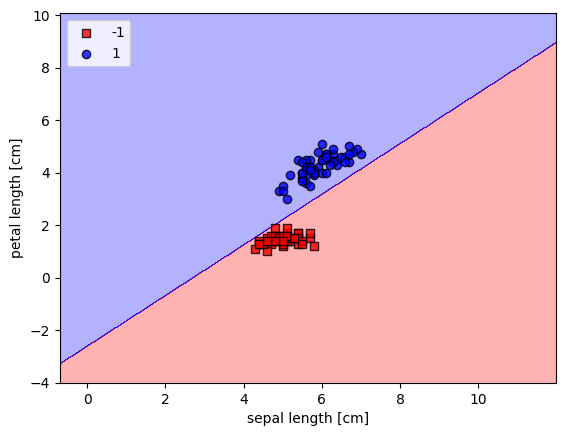

In [ ]:
plot_decision_regions(X, y, classifier=ppn)
plt.xlabel('sepal length [cm]')
plt.ylabel('petal length [cm]')
plt.legend(loc='upper left')


# plt.savefig('images/02_08.png', dpi=300)
plt.show()

Using the decision-region plotting function above, this section plots the decision regions produced after each of the first 10 training epochs, with learning rate = 0.005 and random seed = 3.

Epoch: 1


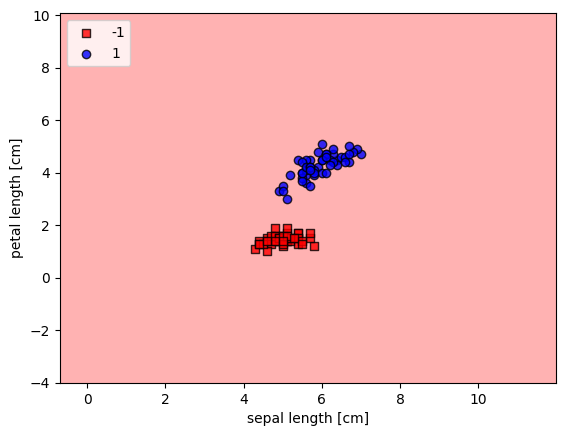

Epoch: 2


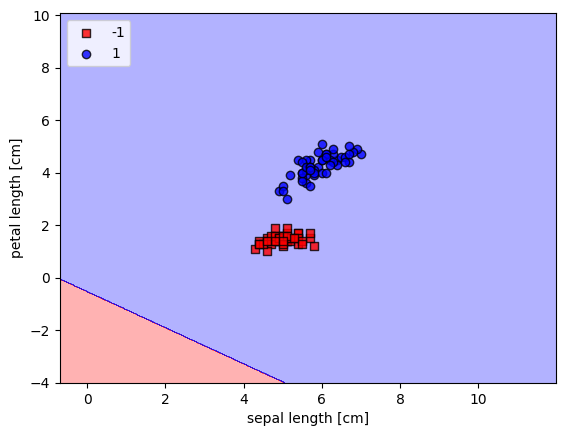

Epoch: 3


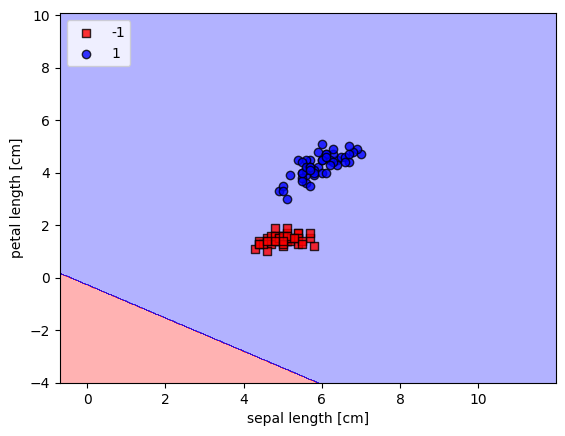

Epoch: 4


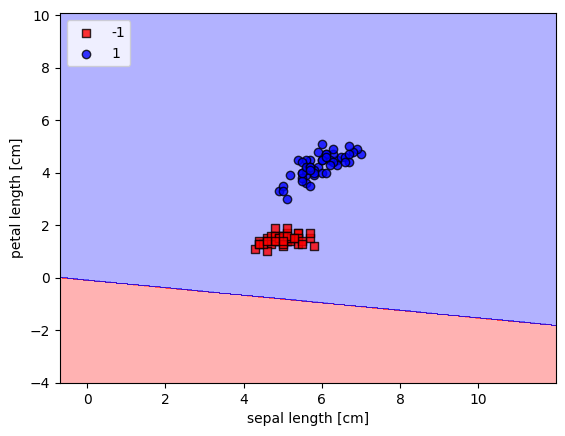

Epoch: 5


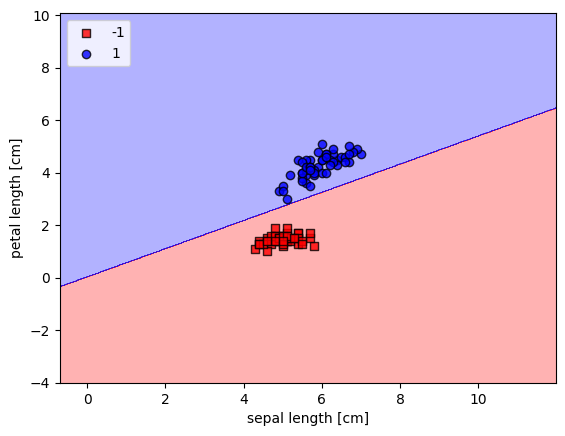

Epoch: 6


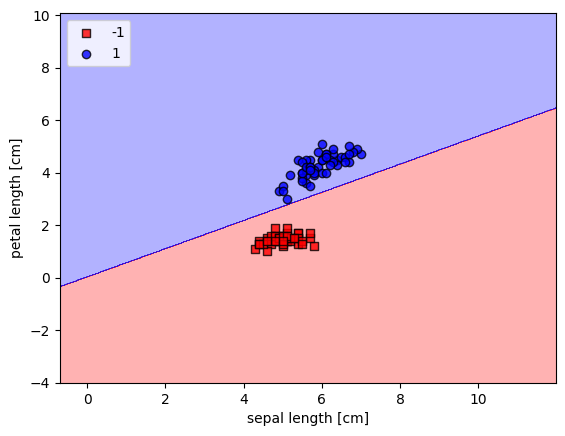

Epoch: 7


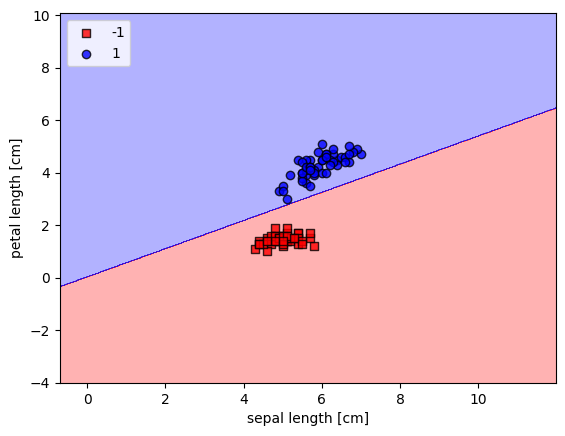

Epoch: 8


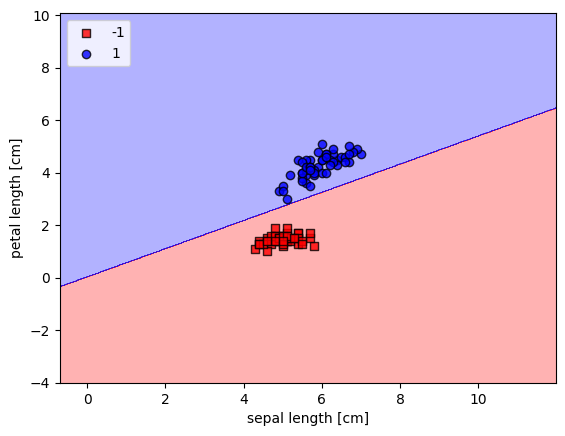

Epoch: 9


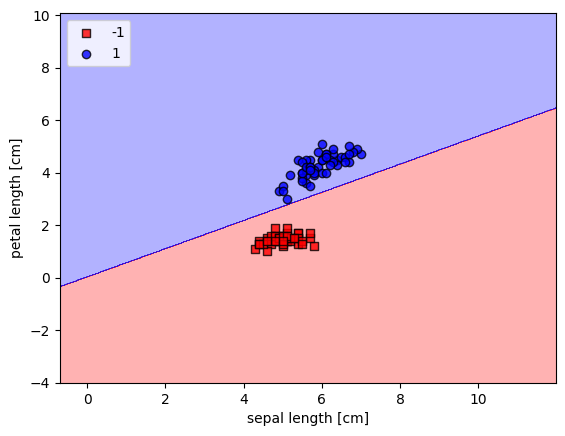

Epoch: 10


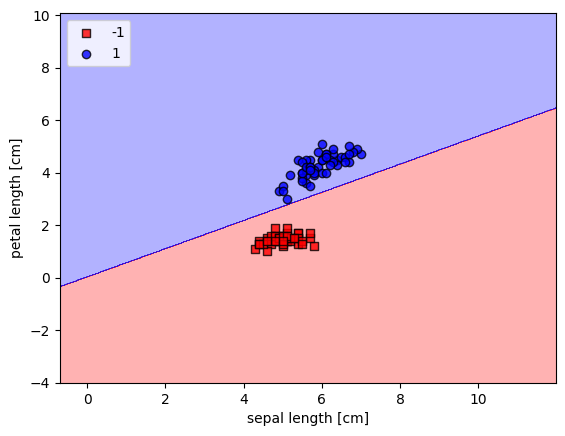

In [ ]:
# Create list to store Perceptron models, each model in the list will be for 1 epoch
ppn_list = []
# For Loop To Generate 10 Models with 1 for each EPOCH
for num_iter in range(0, 10):
  # Initialize Perceptron - Using num_iter loop variable to set max number of iterations for the model
  # By setting n_iter=num_iter, we create 10 models that stop at each epoch (0 - 9)
  ppn = Perceptron(eta=0.005, n_iter=num_iter, random_state=3)
  # Train Perceptron on X, y data
  ppn.fit(X,y)
  # Add Perceptron to Model List
  ppn_list.append(ppn)
# Loop through Perceptron Model List
for index, ppn_iter in enumerate(ppn_list):
  print("Epoch: " + str(index + 1))
  # Using the function above and each instance of the Perceptron Model, plot decision region
  plot_decision_regions(X, y, ppn_iter)
  # Apply Axis Labels and Legend to the Plot
  plt.xlabel('sepal length [cm]')
  plt.ylabel('petal length [cm]')
  plt.legend(loc='upper left')
  plt.show()


-----------------------
-----------------------
-----------------------


## <font color='#008DFF'> **Section 4: Changing the data order in training**



The data arrays (X, y) are currently organized so that all data points with a given label (e.g. 'Setosa') lie in a contiguous block. This section checks how changing that ordering affects the number of iterations a perceptron needs to converge, by generating a random shuffle (permutation) of the data and re-running training on it.

In [ ]:
# establish a random shuffle
s = np.arange(len(y))
np.random.shuffle(s)
# shuffle sample
X_shuffle = X[s];
y_shuffle = y[s];


Using a learning rate small enough that convergence takes 20 or more iterations, the perceptron is trained on both the original and the shuffled data, and the error curves for both runs are plotted for comparison.

Unshuffled
Number of iterations: 40


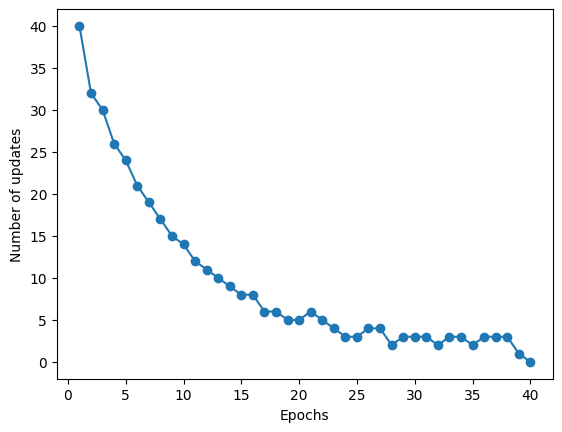

Shuffled
Number of iterations: 21


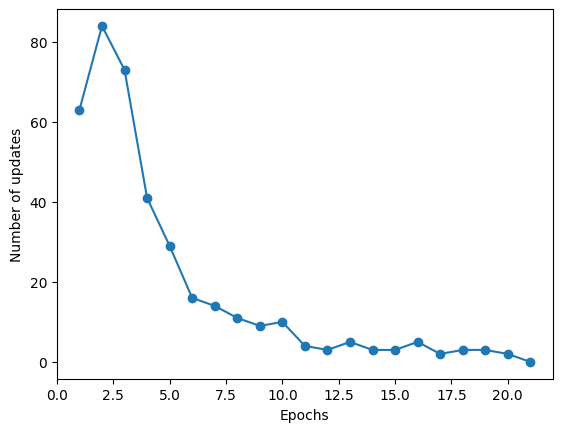

In [ ]:
# Using a learning rate from Question 1 - 40+ iterations
eta = 0.00001
# Initialize Perceptron Model using eta and setting max iterations at 200 and random_state = 2
ppn = Perceptron(eta=eta, n_iter=100, random_state=1)
# Train the Perceptron Model on the Unshuffled Data
ppn.fit(X, y)
# Plot the errors - using code from Question 2
print("Unshuffled")
print("Number of iterations: " + str(ppn.iter_trained))
plt.plot(range(1, len(ppn.errors_) + 1), ppn.errors_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Number of updates')

plt.show()
# Train the Perceptron Model on the Shuffled Data
ppn.fit(X_shuffle, y_shuffle)
# Plot the errors - using code from Question 2
print("Shuffled")
print("Number of iterations: " + str(ppn.iter_trained))
plt.plot(range(1, len(ppn.errors_) + 1), ppn.errors_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Number of updates')

plt.show()

Part (iv)
<br>
Above we have plotted the errors vs epochs for each perceptron model. The first graph is for the unshuffled data. The graph shows that as the number epochs increases, the number of updates that need to be done, decreases. It looks to be an exponential relationship since as the number of epochs increases the rate of change in the number of updates for each epoch decreases. The second graph is for the shuffled data. This graph at first increases in the number of updates going from the first epoch to the second. After the second epoch, the graph follows a similar pattern as the first graph - an exponential decay. There is a difference in the graphs between the unshuffled and shuffled data. Even with the same learning rate and random state parameters, the perceptron models perform vastly different. The unshuffled data takes 40 iterations and the shuffled data takes 21 iterations. This shows that the order of the data points matter when training a perceptron model. This makes sense, weights are adjusted after examining each data point, so the order of the points will alter how the weights are adjusted and subsequently how many iterations it will take to converge.

-----------------------
-----------------------
-----------------------


This section considers a linear transformation of a 2D dataset $X$: each point $X_j = (X_{j,1}, X_{j,2})$ is mapped to $\tilde{X_j} = (aX_{j,1} - c,\ bX_{j,2} - c)$ for constants $a$, $b$, $c$. It explores whether linear separability is preserved under this transformation — both empirically, by plotting a transformed version of the Iris dataset, and theoretically, by working out how the weights of a perceptron trained on the original data would need to change for the transformed data, and what issues could arise. It also compares this derivation against an LLM's answer to the same question, checking it for correctness.

If the original dataset is linearly separable, and we apply a linear transformation to it. The transformed dataset is also linearly separable. If each point in the dataset is transformed in the same way, than separability is maintained. If the linear transformation is rotation, scaling, on translation the separability is perserved. If the transformation is projection (which it is not here), then the separability is not perserverd (or at least very likely to not be preserved). If there exists a good perceptron for the original data set, this is how the weights for the perceptron would change based on the linear transformation described above. The scaling linear transformation is the only transformation that would affect the weights w (w1, w2). The translation would not affect the weights, as moving all data points the same amount to the left, right, up, or down would not affect the slope of the hyperplane separating the points. The translation would only affect the w0 weight which in the context of X * wT + w0 is the y-intercept. So w1 would be multiplied by 1/a and w2 would be multipled by 1/b. w1' = w1 / a. w2' = w2 / b. And w0' would be equal to w0 + c(w1' + w2'). There may be issues that arise from doing the linear transformation. If a or b is equal to 0, this will cause the model to drop one of its features from consideration. This may cause separability to not be preserved. By scaling the weights and features by an amount this may affect the performance of the model and may increase the number of epochs it will take to converge.

-----------------------
-----------------------
-----------------------


## <font color='#008DFF'> **Section 6: Linear regression with numpy 1-liners**

In [1]:
# here we initialize a random data matrix X and random numerical labels y
import numpy as np

X = np.random.randn(10,3)
y = np.random.randn(10,1)

# we also initialize a hypothetical hyperplane defined by w and b
w = np.random.randn(1,3)
b = -1


In [2]:
# (i) find the numerical labels predicted by the model (w,b) for the points in X
#     your code should be a single numpy line
#     hint: we wrote this equation for a single point x in class
#           try to generalize it by expressing everying in terms of matrices

# your code goes here

y_predicted = np.dot(X, w.T) + b


In [3]:
# (ii) find the updated weights after one application of gradient descent with lr = 0.1
#      your code should be a single numpy line

y_ = np.random.randn(10,1)

w_updated, b_updated = w - 0.1 * (np.dot((np.dot(X, w.T) + b - y_).T, X)), b - 0.1 * (np.sum(np.dot(X, w.T) + b - y_))


-----------------------
-----------------------
-----------------------
